DATASET ANALYSIS
----------------------------------------
Dataset shape: (569, 30)
Number of features: 30
Number of classes: 2
Class names: ['malignant' 'benign']

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520      

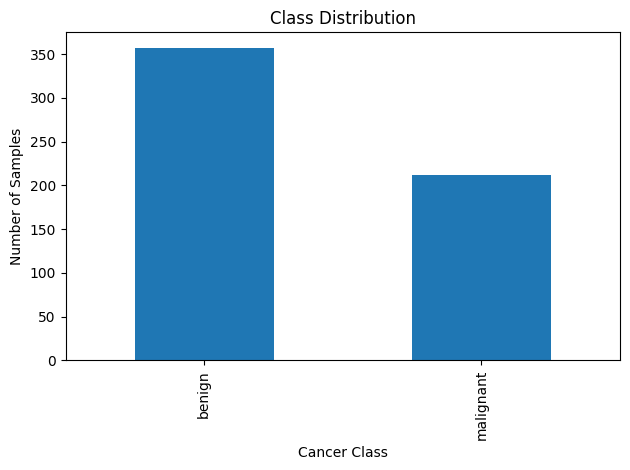


Training samples: 455
Testing samples: 114

MODEL: Decision Tree
Accuracy: 0.9123
Precision: 0.9559
Recall: 0.9028
F1-score: 0.9286

Confusion Matrix:
[[39  3]
 [ 7 65]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



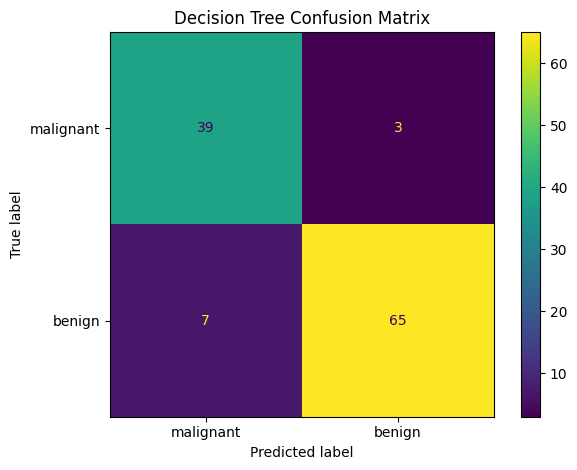


MODEL: Random Forest
Accuracy: 0.9561
Precision: 0.9589
Recall: 0.9722
F1-score: 0.9655

Confusion Matrix:
[[39  3]
 [ 2 70]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



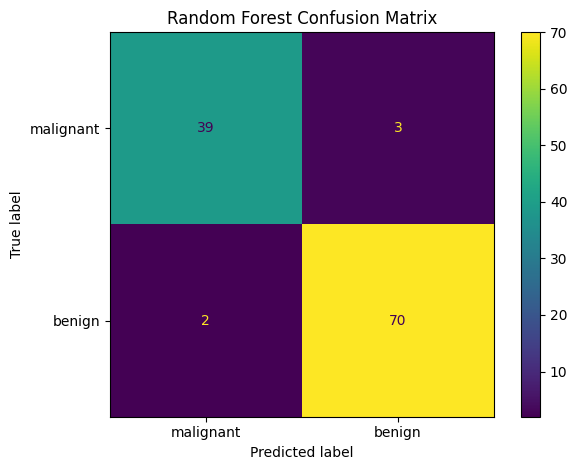


MODEL: SVM
Accuracy: 0.9825
Precision: 0.9861
Recall: 0.9861
F1-score: 0.9861

Confusion Matrix:
[[41  1]
 [ 1 71]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



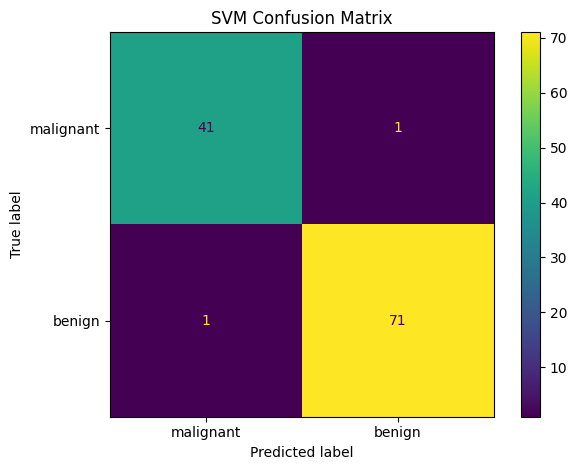


FINAL MODEL COMPARISON
        Model  Accuracy  Precision  Recall  F1-score
Decision Tree    0.9123     0.9559  0.9028    0.9286
Random Forest    0.9561     0.9589  0.9722    0.9655
          SVM    0.9825     0.9861  0.9861    0.9861


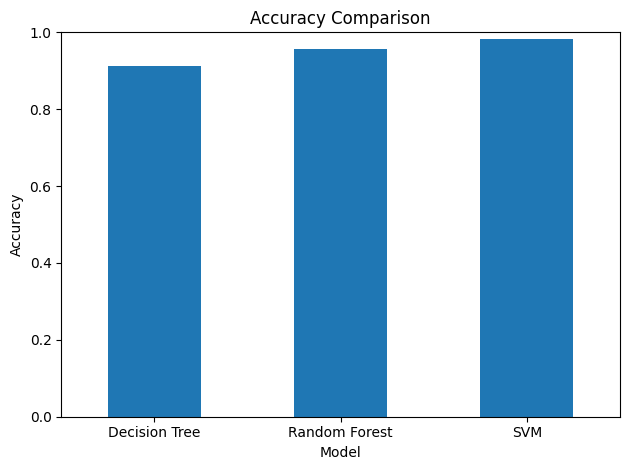


Best model based on test accuracy: SVM
Best accuracy: 98.25 %


In [3]:

# Classification using Decision Tree, Random Forest and SVM
# Dataset: Breast Cancer Wisconsin (public dataset)

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

# 1. Load dataset
dataset = load_breast_cancer()

X = pd.DataFrame(
    dataset.data,
    columns=dataset.feature_names
)

y = pd.Series(dataset.target, name="target")

print("DATASET ANALYSIS")
print("-" * 40)
print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Number of classes:", len(dataset.target_names))
print("Class names:", dataset.target_names)

# 2. Explore the dataset
df = X.copy()
df["target"] = y

print("\nFirst five rows:")
print(df.head())

print("\nStatistical summary:")
print(X.describe().round(2))

print("\nMissing values:")
print(X.isnull().sum().sum())

print("\nClass distribution:")
print(y.map(dict(enumerate(dataset.target_names))).value_counts())

# 3. Visualize class distribution
y.map(dict(enumerate(dataset.target_names))).value_counts().plot(
    kind="bar", title="Class Distribution"
)
plt.xlabel("Cancer Class")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

# 4. Preprocess the data
# Split before scaling to avoid data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Feature scaling for SVM
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 5. Create models using built-in functions
models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    "SVM": SVC(
        kernel="rbf"
    )
}

results = []

# 6. Train and evaluate models
for name, model in models.items():

    print("\n" + "=" * 50)
    print("MODEL:", name)
    print("=" * 50)

    if name == "SVM":
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-score:", round(f1, 4))

    print("\nConfusion Matrix:")
    cm = confusion_matrix(y_test, y_pred)
    print(cm)

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=dataset.target_names,
        zero_division=0
    ))

    # Plot confusion matrix
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=dataset.target_names
    ).plot()
    plt.title(name + " Confusion Matrix")
    plt.tight_layout()
    plt.show()

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })

# 7. Compare all models
comparison = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")
print(comparison.round(4).to_string(index=False))

# 8. Plot accuracy comparison
comparison.plot(
    x="Model",
    y="Accuracy",
    kind="bar",
    legend=False,
    ylim=(0, 1),
    title="Accuracy Comparison"
)

plt.ylabel("Accuracy")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 9. Identify the best model by accuracy
best = comparison.loc[comparison["Accuracy"].idxmax()]

print("\nBest model based on test accuracy:", best["Model"])
print("Best accuracy:", round(best["Accuracy"] * 100, 2), "%")
